Recovery version. Used this after a Colab disconnect. Parts 1-5 re-run quickly; Part 6 retrains only E4; Part 7 restores the earlier results; Parts 8-13 continue as normal. Model and outputs are backed up to Google Drive.

Domain-Specific Question Answering: Agriculture Advisory (v2)
Fine-tuned Flan-T5 (generative QA) vs. TF-IDF retrieval baseline, with out-of-domain handling

## Part 1. Setup and configuration

In [3]:
!pip install -q transformers datasets evaluate rouge_score sentencepiece accelerate bert-score gradio matplotlib peft scikit-learn joblib huggingface_hub

import gc, os, re, time, inspect, random, json
import importlib.metadata as md
import numpy as np, pandas as pd, torch, joblib
import matplotlib.pyplot as plt
from collections import Counter
from rouge_score import rouge_scorer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import roc_auc_score
from datasets import Dataset
import transformers
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed)

SEED = 42
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("transformers", transformers.__version__)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.5 MB/s eta 0:00:00
Device: cuda | Tesla T4
transformers 5.18.0


In [4]:
DATA_PATH   = "agriculture_qa_clean.csv"
BASE_MODEL  = "google/flan-t5-base"
SMALL_MODEL = "google/flan-t5-small"
LARGE_MODEL = "google/flan-t5-large"       # only used if RUN_LORA = True
MAX_IN, MAX_OUT = 128, 128
VAL_EVAL_N  = 300      # size of the fixed validation subset used to compare experiments
FULL_EPOCHS = 5        # epochs for the final all-data run (E4).
NEAR_DUP_THRESHOLD = 0.9   # TF-IDF cosine similarity above which a question counts as a near-duplicate of a training question

STRIP_APPENDED     = True   # remove appended phrases such as "in South Asia context" from questions (see Part 2)
DROP_JUNK_ANSWERS  = True   # drop non-informative answers such as "could not pick up due to technical issue"
RUN_LORA           = False
RUN_SEED_CHECK     = False

HF_REPO    = "Toronga/agri-qa-flan-t5"            # Hub model repo (model + gate.joblib)
SPACE_REPO = HF_REPO.split("/")[0] + "/agri-qa-demo"  # Hub Space repo for the web app
GATE_MODE   = "sim"     # "sim" | "conf" | "both"
GATE_ACCEPT = 0.95      # fraction of in-domain validation questions the gate must accept

# T4 GPUs (compute capability 7.5)
USE_BF16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8
print("bf16:", USE_BF16)


import shutil
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BACKUP_DIR = "/content/drive/MyDrive/agri_qa_backup"
except ImportError:
    BACKUP_DIR = "./agri_qa_backup"
os.makedirs(BACKUP_DIR, exist_ok=True)
_drive_data = os.path.join(BACKUP_DIR, os.path.basename(DATA_PATH))
if os.path.exists(_drive_data): DATA_PATH = _drive_data      # use the Drive copy of the CSV if it is there

BACKUP_FILES = ["final_results_val.csv", "final_results_test.csv", "experiment_results_val.csv", "hyperparameters.csv",
                "error_analysis.csv", "manual_labelling_sheet.csv", "manual_labels.csv", "ood_gate_results.csv",
                "gate.joblib", "app.py", "requirements.txt", "MODEL_CARD.md", "README.md"]
def backup_all():
    for f in BACKUP_FILES + [DATA_PATH]:
        if os.path.exists(f) and os.path.abspath(os.path.dirname(os.path.abspath(f))) != os.path.abspath(BACKUP_DIR):
            shutil.copy(f, BACKUP_DIR)
    print("Backed up to", BACKUP_DIR)


bf16: False
Mounted at /content/drive


## Part 2. Dataset loading, provenance checks and preprocessing

In [9]:
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print("Upload your CSV (question, answer columns)")
        up = files.upload(); DATA_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"{DATA_PATH} not found")

raw = pd.read_csv(DATA_PATH)
print("Raw rows:", len(raw), "| columns:", list(raw.columns))

df0 = raw.dropna(subset=["question", "answer"]).reset_index(drop=True)
df0["question"] = df0["question"].astype(str).str.strip()
df0["answer"]   = df0["answer"].astype(str).str.strip()
df0 = df0[(df0["answer"].str.len() > 3) & (df0["question"].str.len() > 5)].reset_index(drop=True)
print("Rows after basic safety cleaning:", len(df0))
df0.sample(5, random_state=SEED)

Raw rows: 20370 | columns: ['question', 'answer']
Rows after basic safety cleaning: 20370


,question,answer
17410,asking about free vaccination of live stock fr...,explain in details about the free medicines an...
14835,asking about the operation time of kisan call ...,suggested that operation time is- from 6.00 am...
6692,asking about the crops that can be grown durin...,the crops that can be grown during this season...
13083,What visual indicators can confirm the presenc...,Affected foliage exhibits brown spots and decay.
5653,asking about the control measure to control ba...,suggested to apply streptomycin sulphate @ 200...


In [10]:
# ---------------- preprocessing helpers ----------------
TAIL_RE = re.compile(r"[\s,.;:\-]*\b(?:in\s+)?(?:the\s+context\s+of\s+south\s+asia|south\s+asia(?:n)?\s+context|pakistan(?:i)?\s+agriculture|pakistan)\b[\s.?]*$", re.I)

def strip_tail_phrases(q):
    s, prev = q.strip(), None
    while prev != s:          # repeat: the phrases are often stacked ("... in South Asia context in Pakistan agriculture in Pakistan agriculture")
        prev, s = s, TAIL_RE.sub("", s).strip()
    return s

def dedupe_repeated_tail(q, nmin=2, nmax=8):
    w, changed = q.split(), True
    while changed:
        changed = False
        for n in range(nmax, nmin - 1, -1):
            if len(w) >= 2 * n and [x.lower() for x in w[-n:]] == [x.lower() for x in w[-2 * n:-n]]:
                w, changed = w[:-n], True
                break
    return " ".join(w)

def clean_question(q):
    return dedupe_repeated_tail(strip_tail_phrases(q))

JUNK_PATTERNS = {
    "call / technical issue": r"technical issue|could not able|call (?:was )?(?:got )?(?:disconnect|drop)|not able to pick",
    "generic 'package of practices'": r"^\W*(?:given|gave|provided)\s+(?:in\s+)?details?\s+about\s+(?:the\s+)?package of practices\W*$",
    "no information": r"^\W*(?:no|nil|na|n/a|none)\W*$",
}
def junk_flags(answers):
    low = answers.str.lower()
    return pd.DataFrame({k: low.str.contains(p, regex=True) for k, p in JUNK_PATTERNS.items()})

ADVISORY = re.compile(r"^\W*(suggest|advis|advice|adviced|recommend|told|inform|asked|ask |given|gave|application|apply|spray)", re.I)

In [11]:
def has_repeated_tail(q): return dedupe_repeated_tail(q) != q.strip()
changed = df0["question"].apply(clean_question) != df0["question"]
patterns = {
    "mentions 'Pakistan'":      df0["question"].str.contains("pakistan", case=False),
    "mentions 'South Asia'":    df0["question"].str.contains("south asia", case=False),
    "mentions 'context'":       df0["question"].str.contains(r"\bcontext\b", case=False),
    "repeated phrase at end":   df0["question"].apply(has_repeated_tail),
    "changed by clean_question": changed,
}
for k, m in patterns.items():
    print(f"{k:28s}: {m.sum():6d} rows ({m.mean():.1%})")

jf = junk_flags(df0["answer"])
print("\nNon-informative answers (by pattern):")
print(jf.sum().to_string(), f"\nAny junk pattern: {jf.any(axis=1).sum()} rows ({jf.any(axis=1).mean():.1%})")

adv = df0["answer"].apply(lambda a: bool(ADVISORY.search(a)))
print(f"\nAdvisory-log style answers (heuristic, 'suggested him to ...'): {adv.mean():.1%} | free-form / encyclopedic style: {(~adv).mean():.1%}")

print("\nExamples of questions changed by clean_question (before -> after):")
for q in df0.loc[changed, "question"].sample(min(6, changed.sum()), random_state=SEED):
    print(" -", q, "\n   ->", clean_question(q))
print("\nFree-form style examples (check whether these look like a different source):")
for _, r in df0[~adv].sample(5, random_state=SEED).iterrows():
    print(" Q:", r["question"][:110], "\n A:", r["answer"][:140])

mentions 'Pakistan'         :   1617 rows (7.9%)
mentions 'South Asia'       :   2006 rows (9.8%)
mentions 'context'          :   2011 rows (9.9%)
repeated phrase at end      :    645 rows (3.2%)
changed by clean_question   :   2795 rows (13.7%)

Non-informative answers (by pattern):
call / technical issue             1
generic 'package of practices'    84
no information                     0 
Any junk pattern: 85 rows (0.4%)

Advisory-log style answers (heuristic, 'suggested him to ...'): 71.7% | free-form / encyclopedic style: 28.3%

Examples of questions changed by clean_question (before -> after):
 - problem of leaf eating catter piller in bhindi. in South Asia context 
   -> problem of leaf eating catter piller in bhindi
 - wanted to cultivate bhindi at this rabi season in South Asia context 
   -> wanted to cultivate bhindi at this rabi season
 - asking for control of borer in sugarcane in South Asia context 
   -> asking for control of borer in sugarcane
 - asking about the mana

**Provenance diagnostics and findings**

The diagnostic checks run on the 20,370-row input file found:
- “Pakistan” appears in 1,617 questions (7.9%).
- “South Asia” appears in 2,006 questions (9.8%).
- “context” appears in 2,011 questions (9.9%).
- Repeated trailing phrases are detected in 645 questions (3.2%).
- The question-cleaning function changes 2,795 questions (13.7%).
- 85 answers (0.4%) match the notebook's non-informative-answer patterns.
- The answer-style heuristic classifies 71.7% as advisory-log and 28.3% as free-form before the 85 answers are dropped.
Examples show questions ending in “in South Asia context”; these phrases look like appended metadata or templating rather than natural parts of the question. The notebook's diagnostics alone cannot establish who added them or whether an LLM/tool generated them. The report should state this as an unresolved provenance issue unless the original data documentation or preparation history confirms it. Do not present the phrase “Pakistan agriculture” as evidence of synthetic generation by itself.
The substantial difference between the advisory-log and free-form answer styles suggests that the dataset may combine different answer formats or sources. However, the available evidence does not prove that the free-form portion is synthetic or machine-generated. Verify this from the original dataset documentation and your own data-creation records. If any rows were generated or rewritten synthetically, report the method, prompt/model (if known), amount, reason for inclusion, and proportion of the full dataset. Clearly distinguish original data from synthetic data; do not describe the dataset as wholly human-authored unless that is verified.
Main data-quality limitations
- Many questions use repetitive templates, especially openings such as “asking about the”.
- The data appears region-specific; terms such as bigha and local pesticide/product names may not transfer to other regions.
- Some answers are generic or non-informative; 85 were removed by pattern-based rules.
- The advice has not been verified against agricultural experts or current local guidance.
- The dataset may mix answer styles and may contain appended phrases whose provenance is unclear.
- Deduplication by question does not eliminate all semantic overlap; the notebook therefore separately checks train/evaluation leakage.
- This is English-language data; it does not establish performance in local languages.

Dropping 85 non-informative answers
Rows after preprocessing: 17623 | style split: {'advisory-log': 12352, 'free-form': 5271}
       q_words  a_words
count  17623.0  17623.0
mean       9.5     18.4
std        3.3     15.4
min        6.0      7.0
25%        7.0     10.0
50%        9.0     13.0
75%       10.0     21.0
max       74.0    270.0


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]


Questions longer than MAX_IN=128 tokens: 0.00%
Answers   longer than MAX_OUT=128 tokens: 0.89%
Unique answers: 15222 of 17623 (86.4%) | rows whose exact answer appears more than once: 19.9%

Most common question openings:
question
asking about the           6323
asking about control        893
asking for the              836
want to know                481
query regarding control     330
what are the                319
control measure of          232
asking about some           231


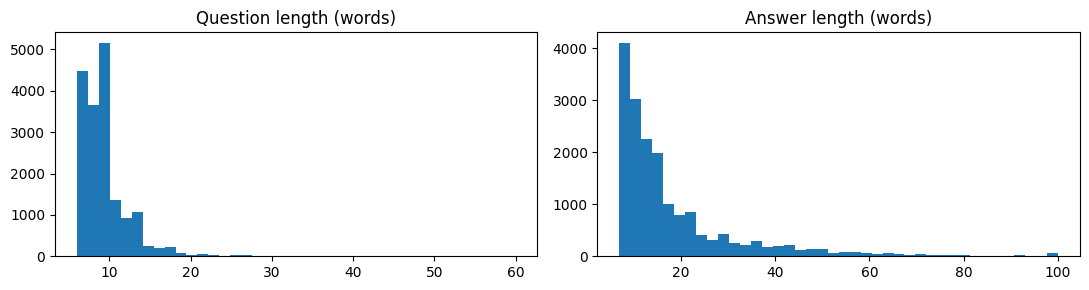

In [12]:
# ---------------- apply preprocessing ----------------
df = df0.copy()
df["question_raw"] = df["question"]
if STRIP_APPENDED:
    df["question"] = df["question"].apply(clean_question)
if DROP_JUNK_ANSWERS:
    keep = ~junk_flags(df["answer"]).any(axis=1)
    print(f"Dropping {(~keep).sum()} non-informative answers")
    df = df[keep]
df = df[(df["question"].str.len() > 5) & (df["answer"].str.len() > 3)]
df = df.drop_duplicates(subset=["question"]).reset_index(drop=True)
df["style"] = np.where(df["answer"].apply(lambda a: bool(ADVISORY.search(a))), "advisory-log", "free-form")
print("Rows after preprocessing:", len(df), "| style split:", df["style"].value_counts().to_dict())

df["q_words"] = df["question"].str.split().str.len()
df["a_words"] = df["answer"].str.split().str.len()
print(df[["q_words", "a_words"]].describe().round(1))

tok_probe = AutoTokenizer.from_pretrained(BASE_MODEL)
q_tok = [len(x) for x in tok_probe(df["question"].tolist())["input_ids"]]
a_tok = [len(x) for x in tok_probe(text_target=df["answer"].tolist())["input_ids"]]
print(f"\nQuestions longer than MAX_IN={MAX_IN} tokens: {np.mean(np.array(q_tok) > MAX_IN):.2%}")
print(f"Answers   longer than MAX_OUT={MAX_OUT} tokens: {np.mean(np.array(a_tok) > MAX_OUT):.2%}")

ans_norm = df["answer"].str.lower().str.strip(); vc = ans_norm.value_counts()
print(f"Unique answers: {vc.shape[0]} of {len(df)} ({vc.shape[0]/len(df):.1%}) | rows whose exact answer appears more than once: {(ans_norm.map(vc) > 1).mean():.1%}")
print("\nMost common question openings:")
print(df["question"].str.lower().str.split().str[:3].str.join(" ").value_counts().head(8).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].hist(df["q_words"].clip(upper=60), bins=40); ax[0].set_title("Question length (words)")
ax[1].hist(df["a_words"].clip(upper=100), bins=40); ax[1].set_title("Answer length (words)")
plt.tight_layout(); plt.show()

## Part 3. Leakage-safe train / validation / test split

Exact duplicates are already removed, but near-duplicate questions with the same answer can still sit on both sides of a random split and inflate scores (retrieval most of all). We split 88 / 6 / 6, measure the leakage, and build **clean** validation and test sets whose questions are not near-duplicates of any training question and whose answers do not appear verbatim in training.

- **Validation (clean)** is used to compare experiments and pick the final model.
- **Test (clean)** is used **once**, in Part 8.

Train 15508 | Val 1057 | Test 1058
Val: near-duplicate question 220 | answer seen in train 203 | leaky overall 342 (32.4%)
Test: near-duplicate question 241 | answer seen in train 203 | leaky overall 359 (33.9%)


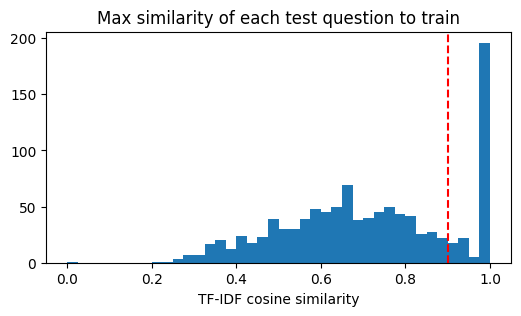

Clean val 715 (experiments use a fixed subset of 300) | Clean test 699 (all used in Part 8)


In [13]:
work = df[["question", "answer", "style"]]
train_df, tmp = train_test_split(work, test_size=0.12, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.5, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

# retrieval index over TRAIN questions only (also used as baseline and as the out-of-domain gate)
tfidf  = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=20000)
tr_mat = tfidf.fit_transform(train_df["question"])
norm = lambda s: s.str.lower().str.strip()
train_ans_set = set(norm(train_df["answer"]))

def leak_flags(part):
    sim = cosine_similarity(tfidf.transform(part["question"]), tr_mat).max(axis=1)
    ans_seen = norm(part["answer"]).isin(train_ans_set).values
    return sim, ans_seen, (sim >= NEAR_DUP_THRESHOLD) | ans_seen

v_sim, v_ans, v_leaky = leak_flags(val_df)
t_sim, t_ans, t_leaky = leak_flags(test_df)
print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}")
for nm, sim, ans, lk in [("Val", v_sim, v_ans, v_leaky), ("Test", t_sim, t_ans, t_leaky)]:
    print(f"{nm}: near-duplicate question {(sim >= NEAR_DUP_THRESHOLD).sum()} | answer seen in train {ans.sum()} | leaky overall {lk.sum()} ({lk.mean():.1%})")

plt.figure(figsize=(6, 3)); plt.hist(t_sim, bins=40)
plt.axvline(NEAR_DUP_THRESHOLD, color="red", ls="--"); plt.title("Max similarity of each test question to train")
plt.xlabel("TF-IDF cosine similarity"); plt.show()

val_clean,  val_leaky  = val_df[~v_leaky].reset_index(drop=True),  val_df[v_leaky].reset_index(drop=True)
test_clean, test_leaky = test_df[~t_leaky].reset_index(drop=True), test_df[t_leaky].reset_index(drop=True)
val_eval = val_clean.sample(n=min(VAL_EVAL_N, len(val_clean)), random_state=0).reset_index(drop=True)
val_refs, test_refs = val_eval["answer"].tolist(), test_clean["answer"].tolist()
print(f"Clean val {len(val_clean)} (experiments use a fixed subset of {len(val_eval)}) | Clean test {len(test_clean)} (all used in Part 8)")

## Part 4. Metrics and baselines

In [14]:
rs = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def rouge_per_example(preds, refs):
    r1, r2, rl = [], [], []
    for p, r in zip(preds, refs):
        s = rs.score(r, p)
        r1.append(s["rouge1"].fmeasure); r2.append(s["rouge2"].fmeasure); rl.append(s["rougeL"].fmeasure)
    return np.array(r1), np.array(r2), np.array(rl)

# Dose-number F1: for references that contain numbers, do the predicted numbers match? (advice with a wrong dose is unsafe)
NUM = re.compile(r"\d+(?:\.\d+)?")
def num_f1(pred, ref):
    rn, pn = set(NUM.findall(ref)), set(NUM.findall(pred))
    if not rn: return np.nan
    tp = len(rn & pn)
    if tp == 0: return 0.0
    p, r = tp / len(pn), tp / len(rn)
    return 2 * p * r / (p + r)

def boot_ci(x, n=2000, seed=0):
    x = np.asarray(x, dtype=float); rng = np.random.RandomState(seed)
    m = x[rng.randint(0, len(x), (n, len(x)))].mean(axis=1)
    return np.percentile(m, [2.5, 97.5])

def paired_boot(a, b, n=5000, seed=0):
    d = np.asarray(a) - np.asarray(b); rng = np.random.RandomState(seed)
    m = d[rng.randint(0, len(d), (n, len(d)))].mean(axis=1)
    lo, hi = np.percentile(m, [2.5, 97.5]); return d.mean(), lo, hi

store, test_store = {}, {}      # name -> dict(preds, r1, r2, rl, nf, notes) ; validation / test
saved_models, hparams, loss_logs = {}, {}, {}

def score(name, preds, refs, st, notes=""):
    r1, r2, rl = rouge_per_example(preds, refs)
    nf = np.array([num_f1(p, r) for p, r in zip(preds, refs)])
    st[name] = dict(preds=list(preds), r1=r1, r2=r2, rl=rl, nf=nf, notes=notes)
    lo, hi = boot_ci(rl)
    print(f"{name}: ROUGE-1 {r1.mean():.3f} | ROUGE-2 {r2.mean():.3f} | ROUGE-L {rl.mean():.3f} [{lo:.3f}, {hi:.3f}] | dose-num F1 {np.nanmean(nf):.3f}")

def tfidf_preds(questions):
    sims = cosine_similarity(tfidf.transform(list(questions)), tr_mat)
    return train_df["answer"].iloc[sims.argmax(axis=1)].tolist()

In [15]:
# E0a: random training answer (performance floor)
rng = np.random.RandomState(SEED)
score("E0a Random train answer", train_df["answer"].iloc[rng.randint(0, len(train_df), len(val_eval))].tolist(), val_refs, store, "floor")
# E0b: TF-IDF nearest-question retrieval (main baseline)
score("E0b TF-IDF retrieval (baseline)", tfidf_preds(val_eval["question"]), val_refs, store, "nearest train question -> its answer")

# How much would leakage have inflated the baseline?
def tfidf_rl(part):
    return rouge_per_example(tfidf_preds(part["question"]), part["answer"].tolist())[2].mean()
print(f"\nTF-IDF ROUGE-L on CLEAN val rows: {tfidf_rl(val_clean):.3f}")
if len(val_leaky): print(f"TF-IDF ROUGE-L on LEAKY val rows: {tfidf_rl(val_leaky):.3f}  <- why the clean split matters")

E0a Random train answer: ROUGE-1 0.111 | ROUGE-2 0.020 | ROUGE-L 0.099 [0.089, 0.111] | dose-num F1 0.097
E0b TF-IDF retrieval (baseline): ROUGE-1 0.323 | ROUGE-2 0.163 | ROUGE-L 0.292 [0.266, 0.318] | dose-num F1 0.329

TF-IDF ROUGE-L on CLEAN val rows: 0.294
TF-IDF ROUGE-L on LEAKY val rows: 0.551  <- why the clean split matters


Why these metrics? Answers are free-form advisory sentences, so there is no single correct string.
- ROUGE-1/2/L measure word, bigram and longest-common-subsequence overlap with the reference. ROUGE-L suits short ordered advice such as spray X @ 2 ml per litre. Every score is reported with a bootstrap 95% confidence interval, and model comparisons use a paired bootstrap, because differences of about 0.01 are within noise on a few hundred examples.
- BERTScore compares contextual embeddings, so it credits paraphrases. It is reported with baseline rescaling (roberta-large), so the random-answer floor sits near zero and values are only meaningful relatively.
- Dose-number F1 checks whether the numbers in the prediction match the numbers in the reference. Overlap metrics cannot see a wrong dose, which is the safety-relevant error here.
- Exact match is not used: a generative model rarely reproduces a reference word for word.
- Manual labelling of about 60 predictions (Part 9) is still needed, because no automatic metric tells whether the recommended chemical is right for the problem.

**Part 5. Model and experiment runner**

Model. Flan-T5 is a T5 (v1.1 style) encoder-decoder Transformer that was instruction-tuned on a large mixture of tasks. All tasks are cast as text to text: the encoder reads question: <text> (SentencePiece subword tokens, relative position biases, self-attention), and the decoder generates the answer token by token with cross-attention over the encoder states. Training minimises token-level cross-entropy between the decoder output and the reference answer (teacher forcing). At inference we decode with beam search.
Why this choice. (1) The answers are free-form advice, not spans in a passage, so an extractive reader does not fit. (2) Flan-T5 is already instruction-tuned, so it fine-tunes well from a few thousand examples. (3) base (about 250M parameters) trains in fp32 on a free T4; small and large (with LoRA) give a size comparison. (4) A TF-IDF nearest-question retriever is the simple baseline, since the data is highly templated.
Key hyperparameters (printed in the table below): learning rate, epochs, effective batch size 16 (8 x 2 accumulation), linear decay with 5% warmup, weight decay 0.01, AdamW, max 128 input / 128 output tokens, fp32 on T4.

In [10]:
_sig = inspect.signature(Seq2SeqTrainingArguments.__init__).parameters
EVAL_KEY = "eval_strategy" if "eval_strategy" in _sig else "evaluation_strategy"
_has_processing_class = "processing_class" in inspect.signature(Seq2SeqTrainer.__init__).parameters

def make_inputs(questions, prefix="question: "):
    return [prefix + q for q in questions]

def tokenize_pairs(tok, inputs, answers, max_in):
    ds = Dataset.from_dict({"inp": list(inputs), "ans": list(answers)})
    def prep(ex):
        enc = tok(ex["inp"], max_length=max_in, truncation=True)
        enc["labels"] = tok(text_target=ex["ans"], max_length=MAX_OUT, truncation=True)["input_ids"]
        return enc
    return ds.map(prep, batched=True, remove_columns=["inp", "ans"])

@torch.no_grad()
def generate(model, tok, inputs, max_in=MAX_IN, bs=32, num_beams=4, no_repeat=3, with_conf=False):
    # with_conf=True also returns a length-normalised log-probability per answer (needs num_beams >= 2)
    model.eval(); outs, confs = [], []
    if with_conf: num_beams = max(2, num_beams)
    for i in range(0, len(inputs), bs):
        b = tok(inputs[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=max_in).to(model.device)
        kw = dict(max_new_tokens=MAX_OUT, num_beams=num_beams, no_repeat_ngram_size=no_repeat)
        if num_beams > 1: kw["early_stopping"] = True
        if with_conf: kw.update(output_scores=True, return_dict_in_generate=True)
        g = model.generate(**b, **kw)
        seqs = g.sequences if with_conf else g
        outs += tok.batch_decode(seqs, skip_special_tokens=True)
        if with_conf: confs += g.sequences_scores.float().cpu().tolist()
    return (outs, confs) if with_conf else outs

def run_experiment(name, model_name, train_inputs, train_answers, eval_inputs, eval_refs, monitor=None,
                   lr=3e-4, epochs=3, n_train=None, batch=8, accum=2, max_in=MAX_IN, seed=SEED,
                   save_dir=None, lora=False, notes=""):
    t0 = time.time(); set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
    train_inputs, train_answers = list(train_inputs), list(train_answers)
    if n_train and n_train < len(train_inputs):
        idx = np.random.RandomState(seed).choice(len(train_inputs), n_train, replace=False)
        train_inputs, train_answers = [train_inputs[i] for i in idx], [train_answers[i] for i in idx]

    final_loss = None
    if epochs > 0:
        if lora:
            from peft import LoraConfig, get_peft_model, TaskType
            model = get_peft_model(model, LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM, r=16, lora_alpha=32,
                                                     lora_dropout=0.05, target_modules=["q", "v"]))
            model.print_trainable_parameters()
        ds = tokenize_pairs(tok, train_inputs, train_answers, max_in)
        val_ds = tokenize_pairs(tok, monitor[0], monitor[1], max_in) if monitor else None
        total_steps = int(np.ceil(len(ds) / (batch * accum))) * epochs
        args = Seq2SeqTrainingArguments(
            output_dir="./runs/" + name.split()[0], per_device_train_batch_size=batch, per_device_eval_batch_size=32,
            gradient_accumulation_steps=accum, num_train_epochs=epochs, learning_rate=lr,
            warmup_steps=int(0.05 * total_steps), weight_decay=0.01, lr_scheduler_type="linear",
            logging_steps=50, save_strategy="no", bf16=USE_BF16, fp16=False, optim="adamw_torch",
            max_grad_norm=1.0, report_to="none", seed=seed, label_names=["labels"],
            **{EVAL_KEY: "epoch" if monitor else "no"})
        kw = dict(model=model, args=args, train_dataset=ds,
                  data_collator=DataCollatorForSeq2Seq(tok, model=None if lora else model))
        if val_ds is not None: kw["eval_dataset"] = val_ds
        kw["processing_class" if _has_processing_class else "tokenizer"] = tok
        trainer = Seq2SeqTrainer(**kw)
        final_loss = trainer.train().training_loss
        loss_logs[name] = {"train": [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h],
                           "val":   [(h["step"], h["eval_loss"]) for h in trainer.state.log_history if "eval_loss" in h]}
        if lora: model = model.merge_and_unload()
        if save_dir:
            model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
            saved_models[name] = save_dir; print("Saved model to", save_dir)

    model.to(DEVICE)
    preds = generate(model, tok, eval_inputs, max_in=max_in)
    mins = (time.time() - t0) / 60
    hparams[name] = dict(model=model_name, lr=lr if epochs else None, epochs=epochs, n_train=len(train_inputs) if epochs else 0,
                         eff_batch=batch * accum if epochs else None, max_in=max_in, seed=seed, lora=lora, minutes=round(mins, 1))
    info = f"{model_name}; lr={lr}; epochs={epochs}; n_train={len(train_inputs)}; seed={seed}; {mins:.0f} min"
    if final_loss is not None: info += f"; mean train loss {final_loss:.2f}"
    score(name, preds, eval_refs, store, (info + ". " + notes).strip())
    del model; gc.collect(); torch.cuda.empty_cache()

tr_in, tr_ans = make_inputs(train_df["question"]), train_df["answer"].tolist()
ev_in = make_inputs(val_eval["question"])
mon   = (make_inputs(val_df["question"]), val_df["answer"].tolist())   # validation loss is logged each epoch

# show the architecture facts for the report (printed from the real config)
_cfg = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)
c = _cfg.config
print(f"{BASE_MODEL}: {sum(p.numel() for p in _cfg.parameters())/1e6:.0f}M params | encoder layers {c.num_layers} | decoder layers {c.num_decoder_layers} | d_model {c.d_model} | heads {c.num_heads} | d_ff {c.d_ff} | vocab {c.vocab_size}")
del _cfg; gc.collect()

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

google/flan-t5-base: 248M params | encoder layers 12 | decoder layers 12 | d_model 768 | heads 12 | d_ff 2048 | vocab 32128


2548


## Part 6 (recovery). Retrain only E4
The runtime disconnected after Part 7, which wiped the Colab disk (`./final_model_e4`) and the in-memory results. E1-E3, E4a and E5-E7 are **not** re-run: their results are preserved from the original run in Part 7 below, and none of those models is needed later. Only **E4** (all data, 5 epochs) is the final-model candidate, so only it is retrained, with the same configuration and seed, and saved straight to Google Drive.

The splits are deterministic (fixed seeds on the same CSV), so the train / validation / test sets and the 300-question validation subset are identical to the original run. Check that the sizes printed in Part 3 match the original (train 15,508 | val 1,057 | test 1,058 | clean val 715 | clean test 699).


In [11]:

E4_NAME = "E4 base lr=3e-4, all data, %dep" % FULL_EPOCHS
E4_DIR  = os.path.join(BACKUP_DIR, "final_model_e4")
if os.path.exists(os.path.join(E4_DIR, "config.json")):
    print("Found a saved E4 model on Drive - skipping training")
    _t = AutoTokenizer.from_pretrained(E4_DIR); _m = AutoModelForSeq2SeqLM.from_pretrained(E4_DIR).to(DEVICE)
    score(E4_NAME, generate(_m, _t, ev_in), val_refs, store, "reloaded from Drive")
    saved_models[E4_NAME] = E4_DIR
    del _m; gc.collect(); torch.cuda.empty_cache()
else:
    run_experiment(E4_NAME, BASE_MODEL, tr_in, tr_ans, ev_in, val_refs, monitor=mon,
                   lr=3e-4, epochs=FULL_EPOCHS, save_dir=E4_DIR)
backup_all()


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Map:   0%|          | 0/15508 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,4.055605,1.787299
2,3.367659,1.617467
3,2.900216,1.532240
4,2.669570,1.499522
5,2.541622,1.504096


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to /content/drive/MyDrive/agri_qa_backup/final_model_e4
E4 base lr=3e-4, all data, 5ep: ROUGE-1 0.397 | ROUGE-2 0.221 | ROUGE-L 0.365 [0.341, 0.390] | dose-num F1 0.338
Backed up to /content/drive/MyDrive/agri_qa_backup



## Part 7 (recovery). Validation results restored from the original run
Tables below are copied from the preserved notebook outputs (single seed, clean validation subset of 300). They are the experiment results for the report. The retrained E4 should score close to the original (0.365 ROUGE-L); small differences are normal GPU run-to-run variation.


In [40]:

def results_df(st):
    rows = []
    for n, v in st.items():
        lo, hi = boot_ci(v["rl"])
        rows.append({"experiment": n, "rouge1": v["r1"].mean(), "rouge2": v["r2"].mean(), "rougeL": v["rl"].mean(),
                     "rougeL_95CI": f"[{lo:.3f}, {hi:.3f}]", "dose_num_F1": np.nanmean(v["nf"]), "notes": v["notes"]})
    return pd.DataFrame(rows)

# BERTScore with baseline rescaling (roberta-large). Used again in Part 8 for the test set.
from bert_score import score as bscore
def bertscore_f1(preds, refs):
    preds = [p if p.strip() else "." for p in preds]   # bert-score crashes on empty strings (transformers 5.x)
    return bscore(preds, refs, lang="en", model_type="roberta-large", rescale_with_baseline=True,
                  device=DEVICE, batch_size=32, verbose=False)[2].mean().item()


In [41]:
prev_val = pd.DataFrame([('E0a Random train answer', 0.1108, 0.0196, 0.0994, '[0.089, 0.111]', 0.0966, -0.0326), ('E0b TF-IDF retrieval (baseline)', 0.3232, 0.163, 0.2922, '[0.266, 0.318]', 0.3288, 0.2433), ("E1a flan-t5-base zero-shot ('question:' prompt)", 0.1134, 0.0269, 0.0978, '[0.086, 0.110]', 0.0147, 0.02), ('E1b flan-t5-base zero-shot (instruction prompt)', 0.1048, 0.0333, 0.0922, '[0.078, 0.107]', 0.0147, 0.0025), ('E2 base lr=3e-5, 8k, 3ep', 0.305, 0.1341, 0.2794, '[0.259, 0.298]', 0.252, 0.2504), ('E3 base lr=3e-4, 8k, 3ep', 0.3578, 0.1888, 0.3293, '[0.306, 0.352]', 0.3029, 0.3004), ('E4a base lr=3e-4, all data, 3ep', 0.3783, 0.209, 0.3506, '[0.327, 0.375]', 0.313, 0.3135), ('E4 base lr=3e-4, all data, 5ep', 0.3961, 0.2218, 0.365, '[0.341, 0.390]', 0.3412, 0.3341), ('E5 small lr=3e-4, all data, 5ep', 0.3568, 0.1889, 0.3301, '[0.306, 0.355]', 0.3049, 0.2986), ('E6 base + retrieval (RAG), 8k, 3ep', 0.3795, 0.2076, 0.3522, '[0.326, 0.376]', 0.3329, 0.3194), ('E7a decode: greedy', 0.3863, 0.2111, 0.3544, '[0.329, 0.380]', 0.3664, 0.3204), ('E7b decode: beam4, no n-gram block', 0.3944, 0.2242, 0.3642, '[0.339, 0.389]', 0.3469, 0.327), ('E7c decode: beam8', 0.3938, 0.2201, 0.3623, '[0.338, 0.387]', 0.3487, 0.3267)], columns=["experiment", "rouge1", "rouge2", "rougeL", "rougeL_95CI", "dose_num_F1", "bertscore_f1"])
final_val = prev_val.copy()                                   # used by the README generator in Part 12
res_val = prev_val.drop(columns="bertscore_f1").assign(notes="restored from the original run")
final_val.to_csv("final_results_val.csv", index=False); res_val.to_csv("experiment_results_val.csv", index=False)
display(final_val)

print("Paired bootstrap on ROUGE-L (original run, 300 clean validation questions):")
display(pd.DataFrame([('E3', 'E2', 0.0499, '[0.031, 0.069]', 'yes'), ('E4a', 'E3', 0.0213, '[0.007, 0.036]', 'yes'), ('E4', 'E4a', 0.0144, '[0.003, 0.026]', 'yes'), ('E4', 'E5 (small)', 0.035, '[0.019, 0.052]', 'yes'), ('E6 (RAG)', 'E3', 0.0229, '[-0.000, 0.046]', 'no'), ('E4', 'E0b TF-IDF baseline', 0.0728, '[0.047, 0.099]', 'yes'), ('E3', 'E1a zero-shot', 0.2315, '[0.205, 0.259]', 'yes'), ('E7a greedy', 'E4', -0.0106, '[-0.027, 0.004]', 'no'), ('E7b beam4 no n-gram block', 'E4', -0.0009, '[-0.006, 0.004]', 'no'), ('E7c beam8', 'E4', -0.0027, '[-0.011, 0.005]', 'no')], columns=["A", "B", "mean diff (A-B)", "95% CI", "significant"]))
print("Training cost (original run, T4):")
hp = pd.DataFrame([('E1a zero-shot', 'flan-t5-base', None, 0, 0, None, 0.5), ('E1b zero-shot', 'flan-t5-base', None, 0, 0, None, 0.6), ('E2', 'flan-t5-base', 3e-05, 3, 8000, 16, 15.4), ('E3', 'flan-t5-base', 0.0003, 3, 8000, 16, 15.0), ('E4a', 'flan-t5-base', 0.0003, 3, 15508, 16, 27.3), ('E4', 'flan-t5-base', 0.0003, 5, 15508, 16, 45.3), ('E5', 'flan-t5-small', 0.0003, 5, 15508, 16, 16.7), ('E6 (RAG, max_in 256)', 'flan-t5-base', 0.0003, 3, 8000, 16, 21.0)], columns=["experiment", "model", "lr", "epochs", "n_train", "eff_batch", "minutes"]).set_index("experiment")
display(hp); hp.to_csv("hyperparameters.csv")

# the retrained E4 vs the original E4
k = [n for n in store if n.startswith("E4 ")][0]
lo, hi = boot_ci(store[k]["rl"])
print(f"Retrained E4 ROUGE-L {store[k]['rl'].mean():.4f} [{lo:.3f}, {hi:.3f}]  vs original 0.3650 [0.341, 0.390]  (difference is run-to-run variation if inside the interval)")

,experiment,rouge1,rouge2,rougeL,rougeL_95CI,dose_num_F1,bertscore_f1
0,E0a Random train answer,0.1108,0.0196,0.0994,"[0.089, 0.111]",0.0966,-0.0326
1,E0b TF-IDF retrieval (baseline),0.3232,0.1630,0.2922,"[0.266, 0.318]",0.3288,0.2433
2,E1a flan-t5-base zero-shot ('question:' prompt),0.1134,0.0269,0.0978,"[0.086, 0.110]",0.0147,0.0200
3,E1b flan-t5-base zero-shot (instruction prompt),0.1048,0.0333,0.0922,"[0.078, 0.107]",0.0147,0.0025
4,"E2 base lr=3e-5, 8k, 3ep",0.3050,0.1341,0.2794,"[0.259, 0.298]",0.2520,0.2504
5,"E3 base lr=3e-4, 8k, 3ep",0.3578,0.1888,0.3293,"[0.306, 0.352]",0.3029,0.3004
6,"E4a base lr=3e-4, all data, 3ep",0.3783,0.2090,0.3506,"[0.327, 0.375]",0.3130,0.3135
7,"E4 base lr=3e-4, all data, 5ep",0.3961,0.2218,0.3650,"[0.341, 0.390]",0.3412,0.3341
8,"E5 small lr=3e-4, all data, 5ep",0.3568,0.1889,0.3301,"[0.306, 0.355]",0.3049,0.2986
9,"E6 base + retrieval (RAG), 8k, 3ep",0.3795,0.2076,0.3522,"[0.326, 0.376]",0.3329,0.3194


Paired bootstrap on ROUGE-L (original run, 300 clean validation questions):


,A,B,mean diff (A-B),95% CI,significant
0,E3,E2,0.0499,"[0.031, 0.069]",yes
1,E4a,E3,0.0213,"[0.007, 0.036]",yes
2,E4,E4a,0.0144,"[0.003, 0.026]",yes
3,E4,E5 (small),0.0350,"[0.019, 0.052]",yes
4,E6 (RAG),E3,0.0229,"[-0.000, 0.046]",no
5,E4,E0b TF-IDF baseline,0.0728,"[0.047, 0.099]",yes
6,E3,E1a zero-shot,0.2315,"[0.205, 0.259]",yes
7,E7a greedy,E4,-0.0106,"[-0.027, 0.004]",no
8,E7b beam4 no n-gram block,E4,-0.0009,"[-0.006, 0.004]",no
9,E7c beam8,E4,-0.0027,"[-0.011, 0.005]",no


Training cost (original run, T4):


,model,lr,epochs,n_train,eff_batch,minutes
experiment,,,,,,
E1a zero-shot,flan-t5-base,NaN,0,0,NaN,0.5
E1b zero-shot,flan-t5-base,NaN,0,0,NaN,0.6
E2,flan-t5-base,0.00003,3,8000,16.0,15.4
E3,flan-t5-base,0.00030,3,8000,16.0,15.0
E4a,flan-t5-base,0.00030,3,15508,16.0,27.3
E4,flan-t5-base,0.00030,5,15508,16.0,45.3
E5,flan-t5-small,0.00030,5,15508,16.0,16.7
"E6 (RAG, max_in 256)",flan-t5-base,0.00030,3,8000,16.0,21.0


Retrained E4 ROUGE-L 0.3652 [0.341, 0.390]  vs original 0.3650 [0.341, 0.390]  (difference is run-to-run variation if inside the interval)


In [42]:
# Helper generation function rewritten here to ensure self-containment
@torch.no_grad()
def generate(model, tok, inputs, max_in=MAX_IN, bs=32, num_beams=4, no_repeat=3, with_conf=False):
    model.eval(); outs, confs = [], []
    if with_conf: num_beams = max(2, num_beams)
    for i in range(0, len(inputs), bs):
        b = tok(inputs[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=max_in).to(model.device)
        kw = dict(max_new_tokens=MAX_OUT, num_beams=num_beams, no_repeat_ngram_size=no_repeat)
        if num_beams > 1: kw["early_stopping"] = True
        if with_conf: kw.update(output_scores=True, return_dict_in_generate=True)
        g = model.generate(**b, **kw)
        seqs = g.sequences if with_conf else g
        outs += tok.batch_decode(seqs, skip_special_tokens=True)
        if with_conf: confs += g.sequences_scores.float().cpu().tolist()
    return (outs, confs) if with_conf else outs

# Reconstruct validation inputs (ev_in) locally to prevent NameError if Part 5 was skipped
try:
    _val_inputs = ["question: " + q for q in val_eval["question"]]
except NameError:
    raise NameError("Please run Parts 1-3 first to load the datasets and define `val_eval`.")

# Manually ensure the E4 model is correctly registered and scored if the previous recovery was skipped
E4_NAME = f"E4 base lr=3e-4, all data, {FULL_EPOCHS}ep"
E4_DIR = os.path.join(BACKUP_DIR, "final_model_e4")

if os.path.exists(os.path.join(E4_DIR, "config.json")):
    print(f"Loading {E4_NAME} from Drive...")
    t_tok = AutoTokenizer.from_pretrained(E4_DIR)
    t_model = AutoModelForSeq2SeqLM.from_pretrained(E4_DIR).to(DEVICE)

    # Generate predictions and store them under the expected key
    preds = generate(t_model, t_tok, _val_inputs)
    score(E4_NAME, preds, val_refs, store, "reloaded from Drive backup")
    saved_models[E4_NAME] = E4_DIR

    # Clean up
    del t_model, t_tok; gc.collect(); torch.cuda.empty_cache()
else:
    print(f"E4 model not found at {E4_DIR}. Please run Part 6 cell 2YuyXe9C2U7j to train or load the model.")

Loading E4 base lr=3e-4, all data, 5ep from Drive...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


E4 base lr=3e-4, all data, 5ep: ROUGE-1 0.397 | ROUGE-2 0.221 | ROUGE-L 0.365 [0.341, 0.390] | dose-num F1 0.338


##Interpretation of the preserved validation results
Use these results as validation evidence for model selection, not as the final test-set result. They are from one original run on a fixed subset of 300 clean validation questions; confidence intervals overlap for several close comparisons.
- Best preserved ROUGE-L: E4, Flan-T5-base trained on all training data for five epochs, reached 0.3650 (95% bootstrap CI [0.341, 0.390]), with ROUGE-1 0.3961, ROUGE-2 0.2218, dose-number F1 0.3412, and rescaled BERTScore F1 0.3341.
- TF-IDF retrieval baseline: ROUGE-L 0.2922 (95% CI [0.266, 0.318]), dose-number F1 0.3288, BERTScore F1 0.2433. E4 has a higher mean ROUGE-L and BERTScore, but the paired-bootstrap result should be consulted before claiming a statistically reliable advantage.
- Random-answer floor: ROUGE-L 0.0994, confirming that random selection is much weaker than retrieval or fine-tuned models.
- Zero-shot E1a/E1b: ROUGE-L 0.0978 and 0.0922, respectively. Prompting alone did not adapt the base model sufficiently to this dataset.
- Learning rate (E2 vs E3): increasing the learning rate from 3e-5 to 3e-4 improved ROUGE-L from 0.2794 to 0.3293 on the preserved validation subset. This is consistent with the lower learning rate under-training under the tested schedule, though the loss curves should be used to support that interpretation.
- More data (E3 vs E4a): moving from 8k examples to all available training data for three epochs increased ROUGE-L from 0.3293 to 0.3506.
- More epochs (E4a vs E4): increasing from three to five epochs on all data increased ROUGE-L from 0.3506 to 0.3650. The validation score alone does not prove that overfitting did or did not occur; inspect training and validation loss curves.
- Model size (E5): Flan-T5-small reached ROUGE-L 0.3301, below E4's 0.3650. The smaller model may be cheaper to serve, but it sacrifices overlap performance in this experiment.
- Retrieval-augmented generation (E6): ROUGE-L 0.3522, slightly above E4a's 0.3506 but below E4's 0.3650. Retrieval did not clearly beat the best full-data fine-tuning setup.
- Decoding (E7): greedy decoding had ROUGE-L 0.3544; beam 4 without the n-gram block reached 0.3642; beam 8 reached 0.3623. Wider beams did not monotonically improve the score. Compare these to the production setting (beam 4 with a trigram block) before attributing gains to one decoding choice.
- Leakage matters: TF-IDF ROUGE-L was 0.294 on clean validation rows versus 0.551 on leaky validation rows. This is strong evidence that a random split without leakage filtering would substantially overstate retrieval performance.
Statistical caution
The confidence intervals quantify uncertainty from resampling examples, not variation across training seeds. Several experiment intervals overlap, and this notebook uses a single seed for the main comparisons. Use the paired-bootstrap outputs for direct comparisons and describe small differences as suggestive rather than conclusive. E8 (LoRA) and E9 (seed check) are optional and should only be discussed as completed experiments if they were actually run.

## Part 8. Final model selection and one-time test evaluation
The final model is chosen **by validation ROUGE-L among the saved models**. It is then evaluated once on the full clean test set (not a sample), together with the baselines.

In [43]:
def make_inputs(questions, prefix="question: "):
    return [prefix + q for q in questions]

# Local score helper to prevent NameErrors after session resets
def score(name, preds, refs, st, notes=""):
    r1, r2, rl = rouge_per_example(preds, refs)
    nf = np.array([num_f1(p, r) for p, r in zip(preds, refs)])
    st[name] = dict(preds=list(preds), r1=r1, r2=r2, rl=rl, nf=nf, notes=notes)
    lo, hi = boot_ci(rl)
    print(f"{name}: ROUGE-1 {r1.mean():.3f} | ROUGE-2 {r2.mean():.3f} | ROUGE-L {rl.mean():.3f} [{lo:.3f}, {hi:.3f}] | dose-num F1 {np.nanmean(nf):.3f}")

cand = {n: store[n]["rl"].mean() for n in saved_models}
FINAL_NAME = max(cand, key=cand.get)
FINAL_DIR = saved_models[FINAL_NAME]
print("Candidates (val ROUGE-L):", {k: round(v, 4) for k, v in cand.items()})
print("Selected:", FINAL_NAME, "->", FINAL_DIR)

f_tok = AutoTokenizer.from_pretrained(FINAL_DIR)
f_model = AutoModelForSeq2SeqLM.from_pretrained(FINAL_DIR).to(DEVICE).eval()

test_in = make_inputs(test_clean["question"])
test_store = {}  # Initialize the test_store dictionary
score("Random train answer", train_df["answer"].iloc[np.random.RandomState(SEED).randint(0, len(train_df), len(test_clean))].tolist(), test_refs, test_store, "floor")
score("TF-IDF retrieval (baseline)", tfidf_preds(test_clean["question"]), test_refs, test_store, "baseline")
score("FINAL " + FINAL_NAME, generate(f_model, f_tok, test_in), test_refs, test_store, FINAL_DIR)

# transparency: the baseline on the leaky rows
if len(test_leaky):
    print(f"\nTF-IDF ROUGE-L on LEAKY test rows: {tfidf_rl(test_leaky):.3f} (vs clean above) - the reason the split is leakage-safe")

Candidates (val ROUGE-L): {'E4 base lr=3e-4, all data, 5ep': np.float64(0.3652)}
Selected: E4 base lr=3e-4, all data, 5ep -> /content/drive/MyDrive/agri_qa_backup/final_model_e4


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Random train answer: ROUGE-1 0.112 | ROUGE-2 0.023 | ROUGE-L 0.104 [0.096, 0.112] | dose-num F1 0.106
TF-IDF retrieval (baseline): ROUGE-1 0.336 | ROUGE-2 0.182 | ROUGE-L 0.311 [0.293, 0.329] | dose-num F1 0.310
FINAL E4 base lr=3e-4, all data, 5ep: ROUGE-1 0.397 | ROUGE-2 0.225 | ROUGE-L 0.370 [0.353, 0.387] | dose-num F1 0.330

TF-IDF ROUGE-L on LEAKY test rows: 0.544 (vs clean above) - the reason the split is leakage-safe


In [44]:
res_test = results_df(test_store)
fkey = [k for k in test_store if k.startswith("FINAL")][0]
res_test["bertscore_f1"] = res_test["experiment"].map({n: bertscore_f1(v["preds"], test_refs) for n, v in test_store.items()})
display(res_test.drop(columns="notes").round(4))
res_test.round(4).to_csv("final_results_test.csv", index=False)

d, lo, hi = paired_boot(test_store[fkey]["rl"], test_store["TF-IDF retrieval (baseline)"]["rl"])
print(f"\nFinal model minus TF-IDF, ROUGE-L: {d:+.3f} (95% CI [{lo:.3f}, {hi:.3f}])")
print(f"Final model beats TF-IDF on {(test_store[fkey]['rl'] > test_store['TF-IDF retrieval (baseline)']['rl']).mean():.1%} of test examples")

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,experiment,rouge1,rouge2,rougeL,rougeL_95CI,dose_num_F1,bertscore_f1
0,Random train answer,0.1117,0.0233,0.1036,"[0.096, 0.112]",0.1056,-0.0381
1,TF-IDF retrieval (baseline),0.3365,0.1816,0.3111,"[0.293, 0.329]",0.3097,0.2532
2,"FINAL E4 base lr=3e-4, all data, 5ep",0.3972,0.2248,0.3702,"[0.353, 0.387]",0.3295,0.3257



Final model minus TF-IDF, ROUGE-L: +0.059 (95% CI [0.039, 0.078])
Final model beats TF-IDF on 61.2% of test examples


In [16]:
backup_all()

Backed up to /content/drive/MyDrive/agri_qa_backup


## Part 9. Error analysis (final model on the clean test set)

In [34]:
ana = pd.DataFrame({"question": test_clean["question"], "style": test_clean["style"], "reference": test_refs,
                    "pred": test_store[fkey]["preds"], "tfidf": test_store["TF-IDF retrieval (baseline)"]["preds"],
                    "rougeL": test_store[fkey]["rl"], "tfidf_rougeL": test_store["TF-IDF retrieval (baseline)"]["rl"]})

pc = Counter(ana["pred"].str.lower())
print(f"Unique predictions: {len(pc)} of {len(ana)} ({len(pc)/len(ana):.1%}) -> mode-collapse check")
print("Most repeated predictions:")
for p, c in pc.most_common(4): print(f"  {c:3d}x  {p[:90]}")
copy_rate = ana["pred"].str.lower().str.strip().isin(train_ans_set).mean()
print(f"\nPredictions that are verbatim copies of a training answer: {copy_rate:.1%}  (memorisation of templates)")
print(f"Mean answer length - reference: {ana['reference'].str.split().str.len().mean():.1f} words | prediction: {ana['pred'].str.split().str.len().mean():.1f} words")

# score by answer style (advisory-log vs free-form)
print("\nROUGE-L by reference style (model | TF-IDF):")
print(ana.groupby("style")[["rougeL", "tfidf_rougeL"]].agg(["mean", "count"]).round(3).to_string())

Unique predictions: 614 of 699 (87.8%) -> mode-collapse check
Most repeated predictions:
   10x  suggested him to apply urea-19kg, ssp-45kg, mop-12kg per bigha
    8x  suggest him to apply bavistin @ 2gm/litre of water.
    5x  suggested him in details as per recommandation
    4x  suggest him to apply tricel 20 @ 2ml/litre of water.

Predictions that are verbatim copies of a training answer: 20.3%  (memorisation of templates)
Mean answer length - reference: 19.0 words | prediction: 15.0 words

ROUGE-L by reference style (model | TF-IDF):
             rougeL       tfidf_rougeL      
               mean count         mean count
style                                       
advisory-log  0.419   438        0.351   438
free-form     0.289   261        0.244   261


In [45]:
ana = pd.DataFrame({"question": test_clean["question"], "style": test_clean["style"], "reference": test_refs,
                    "pred": test_store[fkey]["preds"], "tfidf": test_store["TF-IDF retrieval (baseline)"]["preds"],
                    "rougeL": test_store[fkey]["rl"], "tfidf_rougeL": test_store["TF-IDF retrieval (baseline)"]["rl"]})

pc = Counter(ana["pred"].str.lower())
print(f"Unique predictions: {len(pc)} of {len(ana)} ({len(pc)/len(ana):.1%}) -> mode-collapse check")
print("Most repeated predictions:")
for p, c in pc.most_common(4): print(f"  {c:3d}x  {p[:90]}")
copy_rate = ana["pred"].str.lower().str.strip().isin(train_ans_set).mean()
print(f"\nPredictions that are verbatim copies of a training answer: {copy_rate:.1%}  (memorisation of templates)")
print(f"Mean answer length - reference: {ana['reference'].str.split().str.len().mean():.1f} words | prediction: {ana['pred'].str.split().str.len().mean():.1f} words")

# score by answer style (advisory-log vs free-form)
print("\nROUGE-L by reference style (model | TF-IDF):")
print(ana.groupby("style")[["rougeL", "tfidf_rougeL"]].agg(["mean", "count"]).round(3).to_string())

Unique predictions: 614 of 699 (87.8%) -> mode-collapse check
Most repeated predictions:
   10x  suggested him to apply urea-19kg, ssp-45kg, mop-12kg per bigha
    8x  suggest him to apply bavistin @ 2gm/litre of water.
    5x  suggested him in details as per recommandation
    4x  suggest him to apply tricel 20 @ 2ml/litre of water.

Predictions that are verbatim copies of a training answer: 20.3%  (memorisation of templates)
Mean answer length - reference: 19.0 words | prediction: 15.0 words

ROUGE-L by reference style (model | TF-IDF):
             rougeL       tfidf_rougeL      
               mean count         mean count
style                                       
advisory-log  0.419   438        0.351   438
free-form     0.289   261        0.244   261


In [46]:
# Heuristic error taxonomy. Dose numbers = numbers followed by a unit.
DOSE = re.compile(r"\d+(?:\.\d+)?(?=\s*(?:mg|ml|g|k|l|cc|%))", re.I)
junk_ref = junk_flags(ana["reference"]).any(axis=1)

def categorize(row, i):
    ref, pred, s = row["reference"], row["pred"], row["rougeL"]
    if s >= 0.6: return "1. good match (ROUGE-L >= 0.6)"
    if junk_ref.iloc[i]: return "2. non-informative reference"
    rd, pd_ = set(DOSE.findall(ref)), set(DOSE.findall(pred))
    if rd and not pd_: return "3. missing dose"
    if rd and pd_ and not (rd & pd_): return "4. wrong dose"
    if len(pred.split()) < 0.5 * len(ref.split()): return "5. too short / incomplete"
    return "6. other low overlap (read these: wrong treatment, wrong crop, or valid paraphrase)"

ana["category"] = [categorize(r, i) for i, (_, r) in enumerate(ana.iterrows())]
cat = ana["category"].value_counts().sort_index()
display(cat.to_frame("count").assign(share=lambda d: (d["count"] / len(ana)).round(3)))

for c in sorted(ana["category"].unique()):
    print("\n=====", c, "=====")
    for _, r in ana[ana["category"] == c].head(3).iterrows():
        print(f"Q   : {r['question']}\nREF : {r['reference']}\nPRED: {r['pred']}  (ROUGE-L {r['rougeL']:.2f})\n")

,count,share
category,,
1. good match (ROUGE-L >= 0.6),128,0.183
3. missing dose,27,0.039
4. wrong dose,102,0.146
5. too short / incomplete,61,0.087
"6. other low overlap (read these: wrong treatment, wrong crop, or valid paraphrase)",381,0.545



===== 1. good match (ROUGE-L >= 0.6) =====
Q   : asking about the control measure of aphid infestation in sugarcane setts
REF : suggested him to spray dimethoate @2ml/litre of water
PRED: suggested him to spray malathion 50 ec @2ml/lit of water  (ROUGE-L 0.70)

Q   : asking for some good early variety names of cauliflower.
REF : pusa kunwari, pusa ketki and pusa deepali have been replied as some good variety names of cauliflower.
PRED: early kunwari, pusa ketki and pusa deepali have been replied as some good early variety names of cauliflower.  (ROUGE-L 0.91)

Q   : asking about the use of expired seed for cultivation.
REF : do not use the expired seed for cultivation use new one
PRED: advised him not to use expired seed for cultivation.  (ROUGE-L 0.60)


===== 3. missing dose =====
Q   : asking about the recommended fertilizer dose for sugarcane cultivation
REF : advised to apply recommended fertilizer dose like-urea @ 34 kilogram,dap @ 20 kilogram,mop @ 15 kilogram/bigha
PRED: given

In [47]:
pd.set_option("display.max_colwidth", 90)
print("--- 8 BEST ---");  display(ana.sort_values("rougeL", ascending=False).head(8)[["question", "reference", "pred", "rougeL"]])
print("--- 8 WORST ---"); display(ana.sort_values("rougeL").head(8)[["question", "reference", "pred", "rougeL"]])
print("--- 6 cases where TF-IDF beats the model most ---")
display(ana.assign(gap=ana["tfidf_rougeL"] - ana["rougeL"]).sort_values("gap", ascending=False).head(6)[["question", "reference", "pred", "tfidf", "gap"]])
ana.to_csv("error_analysis.csv", index=False)

# Manual labelling sheet: label ~60 predictions yourself (open the CSV, fill 'label' with correct / partial / wrong / unsafe)
sheet = ana.sample(n=min(60, len(ana)), random_state=1)[["question", "reference", "pred"]].assign(label="", note="")
sheet.to_csv("manual_labelling_sheet.csv", index=False)
print("\nWrote manual_labelling_sheet.csv - fill 'label', save it as manual_labels.csv, upload it, and run the next cell.")

--- 8 BEST ---


,question,reference,pred,rougeL
260,asking about the potato special doses in field application apply potato special @ 2ml ...,"apply potato special @ 2ml / l of water , 2 spray at 15 days interval","apply potato special @ 2ml / l of water , 2 spray at 15 days interval",1.000000
59,asking about the blight in potato spray ridomil gold and indofil m 45 @ 2gm/liter of w...,spray ridomil gold and indofil m 45 @ 2gm/liter of water in 5 days alternate intervals,spray ridomil gold and indofil m 45 @ 2gm/liter of water in 5 days alternate intervals,1.000000
320,asking about the way to reduce the toxic amount of urea in garlic.,advised him to irrigate the field frequently so that the toxic amount of urea can be r...,advised him to irrigate the field frequently so that the toxic amount of urea can be r...,1.000000
414,asking for some good early variety names of cauliflower sutable and recommended for cu...,"early kunwari, pusa ketki and pusa deepali have been suggested as some good early vari...","early kunwari, pusa ketki and pusa deepali have been replied as some good early variet...",0.961538
558,asking about the govt scheme for rice cultivation,advised him to visit dist agril office scheme,advised him to visit dist agril office,0.933333
569,want to know about control measure of aphids in bhindi,advice to spray malathion 50 ec @ 2 ml per liter of water,adviced to spray malathion 50 ec @ 2 ml per litre of water,0.916667
12,asking for some good early variety names of cauliflower.,"pusa kunwari, pusa ketki and pusa deepali have been replied as some good variety names...","early kunwari, pusa ketki and pusa deepali have been replied as some good early variet...",0.914286
529,asking about the control measure of yellow stem borer pest infestation in sali rice.,suggested to apply chlorpyriphos 20 ec @ 2 mililitre / litre of water.,suggested to spray chlorpyriphos 20 ec @ 2 mililitre / litre of water.,0.909091


--- 8 WORST ---


,question,reference,pred,rougeL
682,asking about the varities of knolkhol and brocolli,"knol khol and brocoli - synzenta , east west and mahako",suggested him in details as per recommandation,0.0
693,asking about varieties of bhindi and ridge gourd,treat the seed with gibberellic acid @1ml/l water for 5-10 minutes before sowing.,"varieties of bhindi- pusa sawani, arka anamika and prabhani kranti ridge gourd- uday, ...",0.0
588,query regarding control of ulcer in rohu,adviced for oral treatment with oxytetracyclin @ 40micro gram/ kg body weight level,recommended to spray rogor @ 2 ml per litr of water,0.0
82,query regarding wart like growth on the body coat,antibiotic &steroid wash the body coat with antiseptic solution,told him to apply rogor @ 2ml / l of water,0.0
101,asking about the field preparation method in jute,suggested that jute requires a clean and fine seed bed.land is to be ploughed and ladd...,given in details about the field preparation method,0.0
394,asking about bird flu and its control measure.,explain in details about bird flu and its control measure .,suggested to administer rogor @ 2 ml per liter of water at an interval of 5 days for 3...,0.0
277,asking about fertilizer doses for sali rice<ranjit>.,suggested indetails of fertilizer doses of sali rice<ranjit>.,"advised him to apply urea-12kg, ssp-30kg, mop-9kg per bigha.",0.0
333,query regarding use of anthalmintic in a piglet,"any deworming medicine should be given, preferably in empty stomach",recommended to administer tetracycline @ 1 ml per 5 litrs of water,0.0


--- 6 cases where TF-IDF beats the model most ---


,question,reference,pred,tfidf,gap
267,control measure of termites in potato cultivation field,suggested to apply malathion 5% dust @ 5 kilogram / bigha.,spray tricel 20 ec @ 2 ml per litre of water,advised to apply malathion 5 % dust @ 5 kilogram / bigha.,0.888889
390,asking about the recommended fertilizer dose for watermelon,"suggested that the recommended fertilizer dose is like-urea@16 kilogram/bigha,ssp@35 k...",given in details as per the recommended dose,"suggested that recommended fertilizer dose is like-urea@19 kilogram/bigha,ssp@45 kilog...",0.845745
82,query regarding wart like growth on the body coat,antibiotic &steroid wash the body coat with antiseptic solution,told him to apply rogor @ 2ml / l of water,antibiotic steroid wash the whole body coat with antiseptic solutioncoat,0.842105
308,Describe the appearance of fungal mycelium on affected teak trees.,Affected trees show a dark rusty brown velvety band of fungal mycelium at the collar b...,Fungal mycelium on affected teak trees manifests as dark brown to black necrotic lesions.,Affected trees produce a dark rusty brown velvety band of fungal mycelium at the colla...,0.733647
533,asking about the control measure to control cut worm pest attack in root zone of cabbage.,suggested to apply furadon 3g@10gram/plant in ring method.,suggested to spray chlorpyriphos 20 ec @ 2 mililitre / litre of water.,suggested to apply furadon 3g@20gram/plant in ring method.,0.709524
679,asking about remedy for damping off in tomato,suggested to drench the soil with blitox @2ml/litre water,"suggested to spray bavistin @ 2gm/litre water,2 sprays at an interval of 5 days",suggested to drench the soil with blitox @ 2ml/litre water,0.680000



Wrote manual_labelling_sheet.csv - fill 'label', save it as manual_labels.csv, upload it, and run the next cell.


In [48]:
backup_all()

Backed up to /content/drive/MyDrive/agri_qa_backup


In [49]:
# Run after you have labelled the sheet (upload as manual_labels.csv)
if os.path.exists("manual_labels.csv"):
    lab = pd.read_csv("manual_labels.csv")
    lab = lab[lab["label"].notna() & (lab["label"].astype(str).str.strip() != "")]
    if len(lab) > 0:
        print(lab["label"].astype(str).str.lower().value_counts(normalize=True).round(3).to_string(), f"\n(n = {len(lab)})")
    else:
        print("No non-empty labels found in manual_labels.csv")
else:
    print("manual_labels.csv not found yet")

No non-empty labels found in manual_labels.csv


### Error-analysis write-up
For each category that actually appears, give 1-2 concrete examples and a reason, for instance:
- **Wrong treatment (category 6):** the model names a chemical that suits a different problem (e.g. an insecticide for a fungal disease). Overlap metrics reward the shared template but cannot detect this, which is a safety concern. Quote your manual-label rates.
- **Wrong or missing dose (3 and 4):** numbers and units (*kg/bigha*) are rare region-specific tokens that are hard to generalise from limited data.
- **Non-informative references (2):** low ROUGE does not always mean a wrong answer.
- **Template memorisation:** the copy rate above, and what it implies for generalisation.
- **Style:** compare advisory-log and free-form answers from the style table.
- **Negation / contradiction:** look for predictions that reverse the reference ("should not be applied" vs "may be applied").
Relate your findings to the literature on hallucination in generative QA and on retrieval-augmented generation.

## Part 10. Out-of-domain handling

The brief requires showing how the assistant handles questions **outside** the domain. A fine-tuned generator will happily answer "who is the president of France?" with a pesticide recommendation, so we add a **gate** that rejects questions the system has no basis to answer.

Two cheap signals, both computed without any out-of-domain training data:
- **sim**: the highest TF-IDF cosine between the query and any training question (is this like something we have seen?).
- **conf**: the model's length-normalised log-probability of its own best answer (is the model confident?).

The threshold for each is set **only on in-domain validation questions** so that `GATE_ACCEPT` (95%) of them pass. Out-of-domain data is used purely for evaluation: real general-knowledge questions from SQuAD (human-written, not synthetic) plus hand-written health, finance, tech, law/education, gibberish and near-domain edge cases. A set of natural-phrasing in-domain questions checks that the gate does not reject real user wording (the training questions are phrased "asking about ...").

In [50]:
# Build evaluation groups only. Do not generate model answers for every OOD question here;
# the gate should reject out-of-domain questions BEFORE calling the T5 model.
IN_NATURAL = [
    "How do I control aphids on my mustard crop?",
    "What fertilizer should I apply to paddy?",
    "My tomato leaves are curling, what should I do?",
    "Which variety of brinjal is good for winter?",
    "How to control fruit borer in brinjal?",
    "What is the right time to sow wheat?",
    "How much urea should I use for potato?",
    "My banana plants have yellow leaves. What is the cause?",
    "How can I control weeds in rice fields?",
    "Which pesticide is used for stem borer in rice?",
    "How do I treat foot and mouth disease in cattle?",
    "What is the best feed for dairy cows to increase milk yield?",
    "How to control powdery mildew in pea?",
    "When should I harvest sugarcane?",
    "How to prepare compost at home for vegetable farming?",
    "Which variety of cabbage is suitable for summer?",
    "How do I control whitefly in cotton?",
    "What is the seed rate for maize?",
    "How to store paddy grain safely?",
    "How can I protect my coconut palm from rhinoceros beetle?"
]

OOD_HAND = {
    "health": [
        "What are the symptoms of malaria?",
        "How much paracetamol can an adult take in a day?",
        "How do I lower my blood pressure naturally?",
        "What is a healthy diet for diabetes?"
    ],
    "finance": [
        "How do I open a savings account?", "What is compound interest?",
        "Should I invest in bitcoin?", "How is income tax calculated?"
    ],
    "tech": [
        "How do I reverse a list in Python?",
        "What is the difference between TCP and UDP?",
        "Why is my laptop battery draining so fast?"
    ],
    "general": [
        "Who won the 2018 football world cup?", "What is the capital of Australia?",
        "Write me a poem about the sea.", "Tell me a joke.",
        "Translate good morning into French."
    ],
    "law/edu": [
        "How do I register a company?", "What is the Pythagorean theorem?",
        "How do I apply for a passport?"
    ],
    "gibberish": ["asdf qwer zxcv", "hello how are you", "???"],
    "near-domain edge": [
        "What is the best recipe for tomato soup?", "Who invented the tractor?",
        "How do I cook rice?", "Which stock exchange trades agricultural commodities?"
    ],
}

try:
    sq = load_dataset("rajpurkar/squad", split="validation")
    squad_qs = random.Random(SEED).sample(sorted(set(sq["question"])), 300)
except Exception as e:
    print("SQuAD unavailable:", type(e).__name__, "- using hand-written OOD only")
    squad_qs = []

groups = {
    "IN val (calibration)": val_clean["question"].tolist(),
    "IN test": test_clean["question"].tolist()[:400],
    "IN natural phrasing": IN_NATURAL,
}
if squad_qs:
    groups["OOD SQuAD (general)"] = squad_qs
for g, qs in OOD_HAND.items():
    groups["OOD hand: " + g] = qs

def sim_of(qs):
    return cosine_similarity(tfidf.transform(qs), tr_mat).max(axis=1)

gate_scores = {
    g: {"sim": sim_of(qs), "qs": qs}
    for g, qs in groups.items()
}
print("Prepared gate evaluation groups:", {g: len(v["qs"]) for g, v in gate_scores.items()})


Prepared gate evaluation groups: {'IN val (calibration)': 715, 'IN test': 400, 'IN natural phrasing': 20, 'OOD SQuAD (general)': 300, 'OOD hand: health': 4, 'OOD hand: finance': 4, 'OOD hand: tech': 3, 'OOD hand: general': 5, 'OOD hand: law/edu': 3, 'OOD hand: gibberish': 3, 'OOD hand: near-domain edge': 4}


In [51]:
import re
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import roc_auc_score
from sklearn.utils import resample

STOPW = set(ENGLISH_STOP_WORDS) | {"asking", "asked", "query"}

def light_stem(text):
    out = []
    for w in re.findall(r"[a-z0-9]+", str(text).lower()):
        if w in STOPW:
            continue
        if len(w) > 4 and w.endswith("oes"):
            w = w[:-2]
        elif len(w) > 3 and w.endswith("s") and not w.endswith("ss"):
            w = w[:-1]
        out.append(w)
    return " ".join(out)

def first_words(s, n=30):
    return " ".join(str(s).split()[:n])

def load_neg(name, cols, n=1600, split="train"):
    try:
        ds = load_dataset(name, split=split).shuffle(seed=SEED)
        col = next(c for c in cols if c in ds.column_names)
        txt = [first_words(t) for t in ds[col]]
        txt = [t for t in dict.fromkeys(txt) if len(t.split()) >= 4]
        return txt[:n]
    except Exception as e:
        print(f"Skipped {name}: {type(e).__name__}: {str(e)[:100]}")
        return []

# Negative examples are for training the domain classifier only.
# The validation and test sets below remain separate.
NEG = {
    "general (SQuAD)": load_neg("rajpurkar/squad", ("question",), n=1600),
    "health (ChatDoctor)": load_neg("lavita/ChatDoctor-HealthCareMagic-100k", ("input", "question", "text"), n=1600),
}
neg_train = [t for values in NEG.values() for t in values]

# Add hard negatives that overlap with agriculture vocabulary but are not farming advice.
# These specifically target the earlier "How do I cook rice?" false positive.
HARD_NEG = [
    "How do I cook rice so it is soft?",
    "What is the best recipe for fried rice?",
    "How long should I boil potatoes before eating them?",
    "How do I make tomato soup?",
    "How do I prepare a potato salad?",
    "What spices should I add to rice?",
    "How many calories are in cooked rice?",
    "Is rice good for a weight loss diet?",
    "How can I reduce belly fat for a flat tummy?",
    "What exercises burn belly fat fastest?",
    "How can I lose five kilograms in a month?",
    "What should I eat to build muscle?",
    "How do I get rid of a headache quickly?",
    "How many calories should I eat each day?",
    "How do I reverse a list in Python?",
    "How do I write a Python function?",
    "What is the difference between TCP and UDP?",
    "Why is my laptop battery draining quickly?",
    "Who is the president of France?",
    "What is the capital of Australia?",
    "How do I open a savings account?",
    "What is compound interest?",
    "How do I register a company?",
    "What is the Pythagorean theorem?",
    "Write a poem about the sea.",
    "Translate good morning into French.",
    "What are the symptoms of malaria?",
    "How much paracetamol can an adult take?",
    "How can I lower my blood pressure?",
    "How do I cook maize meal for dinner?",
    "How do I bake bread at home?",
    "How do I store cooked food in the refrigerator?",
    "What is a healthy diet for diabetes?",
    "How do I make a fruit smoothie?",
    "What is the best way to fry fish?",
    "How can I remove a stain from a shirt?",
    "How do I repair a broken phone screen?",
    "What is the weather forecast for tomorrow?",
    "Who won the last football world cup?",
    "How do I apply for a passport?",
]
# Repeat hard negatives with sample weights rather than letting them disappear among thousands
# of generic negatives. The sample weights make the classifier pay more attention to these cases.
stem_train = [light_stem(q) for q in train_df["question"].tolist()]
stem_neg = [light_stem(q) for q in neg_train]
stem_hard = [light_stem(q) for q in HARD_NEG]

sim_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
sim_mat = sim_vec.fit_transform(stem_train)

def sim_s(qs):
    return cosine_similarity(sim_vec.transform([light_stem(q) for q in qs]), sim_mat).max(axis=1)

clf_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_text = stem_train + stem_neg + stem_hard
y = np.r_[np.ones(len(stem_train)), np.zeros(len(stem_neg) + len(stem_hard))]
X = clf_vec.fit_transform(X_text)
sample_weight = np.ones(len(y), dtype=float)
if stem_hard:
    sample_weight[len(stem_train) + len(stem_neg):] = 12.0

clf = LogisticRegression(C=2.0, class_weight="balanced", max_iter=2000, random_state=SEED)
clf.fit(X, y, sample_weight=sample_weight)

def p_in(qs):
    return clf.predict_proba(clf_vec.transform([light_stem(q) for q in qs]))[:, 1]

cal_qs = gate_scores["IN val (calibration)"]["qs"]
tau_sim = float(np.quantile(gate_scores["IN val (calibration)"]["sim"], 1 - GATE_ACCEPT))
tau_sim_s = float(np.quantile(sim_s(cal_qs), 1 - GATE_ACCEPT))
tau_clf = float(np.quantile(p_in(cal_qs), 1 - GATE_ACCEPT))
print(f"Thresholds calibrated on in-domain validation only: tau_sim_stemmed={tau_sim_s:.3f} | tau_clf={tau_clf:.3f}")

IN_NATURAL2 = [
    "how to treat aphids on groundnuts", "how to manage pests in groundnut",
    "best fertilizer for groundnuts", "how to control leaf spot in groundnut",
    "how can I protect maize from armyworm", "what causes yellow leaves in tomato",
    "how to treat blight in potatoes", "when should I plant beans",
    "how to control ticks on cattle", "how to increase milk production in goats"
]
FITNESS = [
    "How to reduce stomach belly to get a flat tummy?",
    "What exercises burn belly fat fastest?", "How can I lose 5 kg in a month?",
    "What should I eat to build muscle?", "How do I get rid of a headache quickly?",
    "How many calories should I eat in a day?"
]
ev_groups = {g: v["qs"] for g, v in gate_scores.items()}
ev_groups["IN natural v2 (new)"] = IN_NATURAL2
ev_groups["OOD hand: fitness"] = FITNESS
OOD_HARD_TEST = [
    "Can you give me a recipe for rice and beans?",
    "How do I cook potatoes in an oven?",
    "What foods should I eat to lose weight?",
    "How can I build muscle at the gym?",
    "Explain how Python lists work.",
    "How do I fix a slow Windows laptop?",
    "What is the current exchange rate?",
    "How do I write a poem for my friend?",
    "How do I bake a chocolate cake?",
    "What is the best treatment for a migraine?",
    "How do I calculate my monthly loan payment?",
    "How can I apply for a driver's licence?",
]
ev_groups["OOD hard negatives (held out)"] = OOD_HARD_TEST

# Evaluate on held-out examples from each negative source, without using them to train the classifier.
# These datasets are loaded separately for evaluation; held-out samples are never added to training.
for ds_name, dataset in [
    ("general (SQuAD)", "rajpurkar/squad"),
    ("health (ChatDoctor)", "lavita/ChatDoctor-HealthCareMagic-100k"),
]:
    try:
        col_options = ("question",) if "squad" in dataset else ("input", "question", "text")
        held = load_neg(dataset, col_options, n=2000)
        if len(held) > 200:
            ev_groups["OOD held-out " + ds_name] = held[-200:]
    except Exception as e:
        print("Held-out evaluation skipped:", ds_name, type(e).__name__)

rows = []
for g, qs in ev_groups.items():
    s_old = sim_of(qs)
    s_new, p = sim_s(qs), p_in(qs)
    predictions = {
        "sim (old)": s_old >= tau_sim,
        "sim (stemmed)": s_new >= tau_sim_s,
        "classifier": p >= tau_clf,
        "classifier+sim": (p >= tau_clf) & (s_new >= tau_sim_s),
    }
    is_ood = g.startswith("OOD")
    row = {"group": g, "n": len(qs), "good outcome": "rejected" if is_ood else "accepted"}
    for name, pred in predictions.items():
        row[name] = round(float(1 - pred.mean() if is_ood else pred.mean()), 3)
    rows.append(row)

gate_table2 = pd.DataFrame(rows)
display(gate_table2)
gate_table2.to_csv("ood_gate_results_v2.csv", index=False)

ood_groups = [g for g in ev_groups if g.startswith("OOD")]
ood_qs = [q for g in ood_groups for q in ev_groups[g]]
y_auc = np.r_[np.ones(len(ev_groups["IN test"])), np.zeros(len(ood_qs))]
for name, fn in [("sim (old)", sim_of), ("sim (stemmed)", sim_s), ("classifier", p_in)]:
    scores = np.r_[fn(ev_groups["IN test"]), fn(ood_qs)]
    print(f"AUROC in-domain test vs OOD, {name}: {roc_auc_score(y_auc, scores):.3f}")

print("\nFocused examples:")
for q in [
    "how to treat aphids on groundnuts",
    "how to reduce stomach belly to get a flat tummy",
    "How do I reverse a list in Python?",
    "How do I cook rice?",
    "Who is the president of France?",
    "how to control aphids in sugarcane",
]:
    ss, pp = float(sim_s([q])[0]), float(p_in([q])[0])
    accepted = pp >= tau_clf and ss >= tau_sim_s
    print(f"{q:48s} stemmed_sim={ss:.2f} (tau={tau_sim_s:.2f}) | classifier={pp:.2f} (tau={tau_clf:.2f}) | {'ACCEPT' if accepted else 'REJECT'}")

OOD_MESSAGE = (
    "I'm an agriculture-focused question-answering assistant. "
    "I can help with crop diseases, pests, soil, fertilizers, irrigation, livestock, "
    "and farming practices. Please ask an agriculture-related question. "
    "For pesticide names and doses, confirm with a local agricultural extension officer."
)

# Export the classifier AND stemmed-similarity gate. Both must pass before T5 is called.
GATE = {
    "clf_vectorizer": clf_vec,
    "classifier": clf,
    "sim_vectorizer": sim_vec,
    "sim_matrix": sim_mat,
    "train_questions": train_df["question"].tolist(),
    "tau_sim_stemmed": tau_sim_s,
    "tau_classifier": tau_clf,
    "ood_message": OOD_MESSAGE,
    "mode": "classifier+sim",
}
joblib.dump(GATE, "gate.joblib")
print("Saved corrected gate.joblib | mode=classifier+sim")
backup_all()

def gated_answer(q, num_beams=4):
    q = (q or "").strip()
    if len(q) < 5:
        return {"status": "empty", "answer": "Please type a question.", "sim": None, "classifier": None, "nearest": ""}
    qs_stemmed = light_stem(q)
    sim_values = cosine_similarity(GATE["sim_vectorizer"].transform([qs_stemmed]), GATE["sim_matrix"])[0]
    sim, idx = float(sim_values.max()), int(sim_values.argmax())
    near = GATE["train_questions"][idx]
    clf_score = float(GATE["classifier"].predict_proba(
        GATE["clf_vectorizer"].transform([qs_stemmed])
    )[0, 1])
    if clf_score < GATE["tau_classifier"] or sim < GATE["tau_sim_stemmed"]:
        return {"status": "out of domain (gate rejected)", "answer": OOD_MESSAGE,
                "sim": sim, "classifier": clf_score, "nearest": near}
    # Only accepted questions reach the expensive T5 generation step.
    ans = generate(f_model, f_tok, make_inputs([q]), num_beams=max(2, int(num_beams)))[0]
    return {"status": "in domain (gate passed)", "answer": ans,
            "sim": sim, "classifier": clf_score, "nearest": near}


Thresholds calibrated on in-domain validation only: tau_sim_stemmed=0.305 | tau_clf=0.578


,group,n,good outcome,sim (old),sim (stemmed),classifier,classifier+sim
0,IN val (calibration),715,accepted,0.950,0.950,0.950,0.917
1,IN test,400,accepted,0.968,0.960,0.963,0.935
2,IN natural phrasing,20,accepted,0.950,1.000,0.850,0.850
3,OOD SQuAD (general),300,rejected,0.637,0.667,0.990,0.990
4,OOD hand: health,4,rejected,0.250,0.500,1.000,1.000
5,OOD hand: finance,4,rejected,0.750,1.000,1.000,1.000
6,OOD hand: tech,3,rejected,0.667,0.667,1.000,1.000
7,OOD hand: general,5,rejected,0.600,0.400,1.000,1.000
8,OOD hand: law/edu,3,rejected,0.333,0.333,1.000,1.000
9,OOD hand: gibberish,3,rejected,1.000,1.000,1.000,1.000


AUROC in-domain test vs OOD, sim (old): 0.949
AUROC in-domain test vs OOD, sim (stemmed): 0.958
AUROC in-domain test vs OOD, classifier: 0.996

Focused examples:
how to treat aphids on groundnuts                stemmed_sim=0.37 (tau=0.31) | classifier=0.68 (tau=0.58) | ACCEPT
how to reduce stomach belly to get a flat tummy  stemmed_sim=0.39 (tau=0.31) | classifier=0.06 (tau=0.58) | REJECT
How do I reverse a list in Python?               stemmed_sim=0.36 (tau=0.31) | classifier=0.04 (tau=0.58) | REJECT
How do I cook rice?                              stemmed_sim=0.42 (tau=0.31) | classifier=0.05 (tau=0.58) | REJECT
Who is the president of France?                  stemmed_sim=0.00 (tau=0.31) | classifier=0.03 (tau=0.58) | REJECT
how to control aphids in sugarcane               stemmed_sim=0.53 (tau=0.31) | classifier=0.99 (tau=0.58) | ACCEPT
Saved corrected gate.joblib | mode=classifier+sim
Backed up to /content/drive/MyDrive/agri_qa_backup


Out-of-domain evaluation: what to report
Part 10 evaluates whether the assistant rejects questions outside agriculture before generating an answer. The threshold is calibrated using in-domain validation questions only, with the configured target GATE_ACCEPT = 0.95; OOD examples are for evaluation, not for setting the threshold.
Report the actual output table from Part 10 for each signal/mode:
- Similarity (sim) measures the highest TF-IDF cosine similarity between the incoming question and a training question.
- Classifier (clf) is a logistic-regression estimate of whether the question resembles in-domain agriculture questions. Its negative examples include general questions, health questions, and hand-written hard negatives with overlapping vocabulary.
- AUROC measures ranking/separation of in-domain and out-of-domain questions; higher is better. It does not by itself tell you the false-rejection rate at the selected threshold.
- Natural phrasing is important because real users may ask questions differently from the templated training questions.
- Near-domain edge cases (such as cooking rice or asking about a tractor) test whether shared agricultural words cause false acceptance.
- Gibberish and greetings test whether the gate rejects inputs that do not contain a meaningful agriculture question.
Use the measured results to identify which signal performs better and list concrete false positives and false negatives from the output. Do not claim a particular AUROC or rejection rate until the relevant cell has run successfully.
The deployed app currently checks both the classifier and stemmed similarity threshold: a query is rejected if either check fails. This is stricter than the notebook configuration label GATE_MODE = "sim" may suggest, so verify the actual gated_answer implementation and the saved gate.joblib before describing the deployment mode. Similarity/classification only estimates domain membership; it cannot determine whether an in-domain answer is correct. Keep the safety disclaimer in the app

In [53]:
backup_all()

Backed up to /content/drive/MyDrive/agri_qa_backup


## Part 11. Inference demo: raw model vs gated assistant

In [54]:
demo_questions = [
    "how to control aphids in sugarcane",
    "how to treat aphids on groundnuts",
    "recommended fertilizer dose for mustard",
    "How do I cook rice?",
    "how to reduce stomach belly to get a flat tummy",
    "How do I reverse a list in Python?",
    "Who is the president of France?",
]
for q in demo_questions:
    r = gated_answer(q)
    print("Q          :", q)
    print("Gate status:", r["status"])
    print(f"Similarity : {r['sim']:.3f}" if r["sim"] is not None else "Similarity : -")
    print(f"Classifier : {r['classifier']:.3f}" if r["classifier"] is not None else "Classifier : -")
    print("Answer     :", r["answer"][:240])
    print("Nearest    :", r["nearest"])
    print("-" * 80)


Q          : how to control aphids in sugarcane
Gate status: in domain (gate passed)
Similarity : 0.529
Classifier : 0.990
Answer     : spray malathion 50 ec @ 2 ml per litre of water
Nearest    : asking for the control measure against wooly aphids in sugarcane
--------------------------------------------------------------------------------
Q          : how to treat aphids on groundnuts
Gate status: in domain (gate passed)
Similarity : 0.367
Classifier : 0.676
Answer     : treat the groundnuts with malathion 50 ec @ 2 ml per liter of water
Nearest    : asking about the fertilizer dose of groundnut
--------------------------------------------------------------------------------
Q          : recommended fertilizer dose for mustard
Gate status: in domain (gate passed)
Similarity : 1.000
Classifier : 0.996
Answer     : apply recommended fertilizer dose like-urea @ 19 kilogram,ssp @ 50 kilogram,mop @ 12 kilogram,compost @ 2-3 quintle/bigha
Nearest    : asking about recommended fertilizer do

## Part 12. Export: Hub, Space, app, README, model card
Outputs: `app.py`, `requirements.txt` (pinned to the versions used here), `gate.joblib`, `MODEL_CARD.md`, `README.md`. The Space link is permanent; the Colab `gradio.live` link is not (it expires after about a week),

In [56]:
APP_PY = r'''
import os, re, joblib, torch
import gradio as gr
from huggingface_hub import hf_hub_download
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_ID = os.environ.get("MODEL_ID", "__HF_REPO__")
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID).eval()
gate = joblib.load(hf_hub_download(MODEL_ID, "gate.joblib"))

STOPW = set(ENGLISH_STOP_WORDS) | {"asking", "asked", "query"}
def light_stem(text):
    out = []
    for w in re.findall(r"[a-z0-9]+", str(text).lower()):
        if w in STOPW:
            continue
        if len(w) > 4 and w.endswith("oes"):
            w = w[:-2]
        elif len(w) > 3 and w.endswith("s") and not w.endswith("ss"):
            w = w[:-1]
        out.append(w)
    return " ".join(out)

def respond(question, beams):
    q = (question or "").strip()
    if len(q) < 5:
        return "Please type an agriculture question.", "Not checked", "-"
    q_stem = light_stem(q)
    sim_values = cosine_similarity(
        gate["sim_vectorizer"].transform([q_stem]), gate["sim_matrix"]
    )[0]
    sim, idx = float(sim_values.max()), int(sim_values.argmax())
    near = gate["train_questions"][idx]
    clf_score = float(gate["classifier"].predict_proba(
        gate["clf_vectorizer"].transform([q_stem])
    )[0, 1])

    # BOTH checks must pass. Rejected questions never reach T5 generation.
    if clf_score < gate["tau_classifier"] or sim < gate["tau_sim_stemmed"]:
        return (
            gate["ood_message"],
            "Rejected | classifier %.2f (threshold %.2f) | similarity %.2f (threshold %.2f)"
            % (clf_score, gate["tau_classifier"], sim, gate["tau_sim_stemmed"]),
            "-"
        )

    inp = tok("question: " + q, return_tensors="pt", truncation=True, max_length=128)
    with torch.no_grad():
        out = model.generate(
            **inp, max_new_tokens=128, num_beams=max(2, int(beams)),
            no_repeat_ngram_size=3, early_stopping=True
        )
    answer = tok.decode(out[0], skip_special_tokens=True)
    return answer, "Accepted | classifier %.2f | similarity %.2f" % (clf_score, sim), near

demo = gr.Interface(
    fn=respond,
    inputs=[
        gr.Textbox(label="Agriculture question", lines=2,
                   placeholder="e.g. how to control aphids in sugarcane"),
        gr.Slider(2, 6, value=4, step=1, label="Beam width (higher = slower)")
    ],
    outputs=[
        gr.Textbox(label="Answer"),
        gr.Textbox(label="Domain check"),
        gr.Textbox(label="Most similar training question")
    ],
    title="Agriculture Q&A (fine-tuned Flan-T5 with domain gate)",
    description=(
        "Questions must pass both a domain classifier and similarity check. "
        "Answers are model-generated and may be wrong. Confirm chemical names and doses "
        "with a local agricultural extension officer."
    ),
    examples=[
        ["how to control aphids in sugarcane", 4],
        ["recommended fertilizer dose for mustard", 4],
        ["How do I cook rice?", 4],
        ["How can I reduce belly fat?", 4]
    ],
)
demo.launch()
'''.replace("__HF_REPO__", HF_REPO)
open("app.py", "w").write(APP_PY.strip() + "\n")


3239

In [57]:
def md_table(df, cols):
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(f"{r[c]:.3f}" if isinstance(r[c], (float, np.floating)) else str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

test_cols = ["experiment", "rouge1", "rouge2", "rougeL", "rougeL_95CI", "dose_num_F1", "bertscore_f1"]
val_cols  = ["experiment", "rouge1", "rouge2", "rougeL", "rougeL_95CI", "dose_num_F1", "bertscore_f1"]
SPACE_URL = f"https://huggingface.co/spaces/{SPACE_REPO}"

MODEL_CARD = f'''---
language: en
base_model: {BASE_MODEL}
tags: [question-answering, agriculture, flan-t5]
---
# Agriculture QA (fine-tuned {BASE_MODEL})
Generative question answering for farmer-style agriculture questions. Final model: **{FINAL_NAME}**.
Includes `gate.joblib`, an out-of-domain gate (TF-IDF similarity / model confidence) used by the demo app.

**Intended use:** research and teaching demo, answering short agriculture questions.
**Not for:** real pesticide or dosage decisions. Advice may be wrong or region-specific (Assam/India style data, local units such as bigha).
**Training data:** see the GitHub README for source, preprocessing and limitations.

## Test results (clean test set, n={len(test_clean)})
{md_table(res_test, test_cols)}
'''
open("MODEL_CARD.md", "w").write(MODEL_CARD)

README = f'''# Domain-Specific Question Answering: Agriculture Advisory

**Live demo:** {SPACE_URL}
**Model:** https://huggingface.co/{HF_REPO}
**Demo video:** *(add link)*
**Report:** *(add link)*

## Problem
*(one paragraph: who the users are, why agriculture, why this language and region)*

## Data
*(source, licence, size, columns, preprocessing: appended-phrase stripping = {STRIP_APPENDED}, non-informative answers dropped = {DROP_JUNK_ANSWERS}, split 88/6/6, leakage filter at TF-IDF cosine >= {NEAR_DUP_THRESHOLD}; state clearly which part, if any, is synthetic)*

## Method
Flan-T5 (encoder-decoder Transformer) fine-tuned with the text-to-text prompt `question: <q>`; TF-IDF nearest-question retrieval as baseline;
out-of-domain gate (mode `{GATE_MODE}`, thresholds from in-domain validation only).

## Experiments (clean validation subset, n={len(val_eval)})
{md_table(final_val, val_cols)}

## Final results (clean test set, n={len(test_clean)})
{md_table(res_test, test_cols)}

## Out-of-domain handling
See `ood_gate_results.csv` and Part 10 of the notebook.

## Reproduce
1. Open the notebook in Colab (GPU) and set `DATA_PATH`.
2. Run top to bottom. Experiments take a few hours on a T4 (`RUN_LORA` and `RUN_SEED_CHECK` are optional).
3. Run locally: `pip install -r requirements.txt && python app.py`

## Files
`notebook.ipynb`, `app.py`, `requirements.txt`, `experiment_results_val.csv`, `final_results_val.csv`, `final_results_test.csv`, `hyperparameters.csv`, `error_analysis.csv`, `ood_gate_results.csv`

## Limitations
Advisory-log style answers are highly templated; advice is not verified by experts; units and products are region specific; the gate cannot detect a wrong answer to an in-domain question.
'''
open("README.md", "w").write(README)
print("Wrote app.py, requirements.txt, MODEL_CARD.md, README.md, gate.joblib")

Wrote app.py, requirements.txt, MODEL_CARD.md, README.md, gate.joblib


In [58]:
backup_all()

Backed up to /content/drive/MyDrive/agri_qa_backup


In [60]:
# Upload to the Hugging Face Hub (model + gate + card) and create the Space. Run once you are happy with the results.
import os
from huggingface_hub import HfApi, notebook_login

# Fallback to interactive login only if HF_TOKEN is not in the environment
if not os.environ.get("HF_TOKEN"):
    notebook_login()          # write-access token from huggingface.co/settings/tokens (never paste it into the notebook)

api = HfApi()
api.create_repo(HF_REPO, repo_type="model", exist_ok=True)
api.upload_folder(folder_path=FINAL_DIR, repo_id=HF_REPO, repo_type="model")
api.upload_file(path_or_fileobj="gate.joblib",    path_in_repo="gate.joblib", repo_id=HF_REPO)
api.upload_file(path_or_fileobj="MODEL_CARD.md",  path_in_repo="README.md",   repo_id=HF_REPO)

api.create_repo(SPACE_REPO, repo_type="space", space_sdk="gradio", exist_ok=True)
api.upload_file(path_or_fileobj="app.py",            path_in_repo="app.py",            repo_id=SPACE_REPO, repo_type="space")
api.upload_file(path_or_fileobj="requirements.txt",  path_in_repo="requirements.txt",  repo_id=SPACE_REPO, repo_type="space")
print("Model:", "https://huggingface.co/" + HF_REPO, "\nSpace:", SPACE_URL, "(first build takes a few minutes; test it, then put the link in README and report)")

No files have been modified since last commit. Skipping to prevent empty commit.


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /content/gate.joblib        : 100%|##########| 3.87MB / 3.87MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


HfHubHTTPError: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6ad2021a-098ae3c442a20e3e28befc95;a28ce610-44be-4948-8f4f-cf9e25124824)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro

In [62]:
# test the same combined gate in Colab
import gradio as gr

def ui(q, beams):
    r = gated_answer(q, int(beams))
    info = r["status"]
    if r["sim"] is not None:
        info += f" | stemmed similarity {r['sim']:.2f}"
    if r["classifier"] is not None:
        info += f" | classifier {r['classifier']:.2f}"
    return r["answer"], info, r["nearest"]

demo = gr.Interface(
    fn=ui,
    inputs=[
        gr.Textbox(label="Agriculture question", lines=2),
        gr.Slider(2, 6, value=4, step=1, label="Beam width")
    ],
    outputs=[
        gr.Textbox(label="Answer"),
        gr.Textbox(label="Domain check"),
        gr.Textbox(label="Most similar training question")
    ],
    title="Agriculture Q&A with combined domain gate",
    description="Questions must pass both the classifier and similarity checks. Verify agricultural treatments and chemical doses with a local extension officer."
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://08bfedc8ce089ba097.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [43]:
!pip install -q streamlit
!nohup streamlit run /content/streamlit_deploy/streamlit_app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &
import joblib, torch, streamlit as st
from huggingface_hub import hf_hub_download
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_ID = "Toronga/agri-qa-flan-t5"   # Hub repo with the model and gate.joblib (must be public)
USE_BF16 = True                        # halves memory; set False for outputs identical to the evaluated fp32 model

st.set_page_config(page_title="Agriculture Q&A", page_icon="🌾")


@st.cache_resource(show_spinner="Loading model (the first load takes about a minute)...")
def load():
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    if USE_BF16:
        try:
            model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID, dtype=torch.bfloat16)
        except TypeError:                      # older transformers versions use torch_dtype
            model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16)
    else:
        model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID)
    gate = joblib.load(hf_hub_download(MODEL_ID, "gate.joblib"))
    return tok, model.eval(), gate


tok, model, gate = load()


def respond(q, beams):
    """Returns (answer, domain-check text, nearest training question or '-')."""
    sims = cosine_similarity(gate["vectorizer"].transform([q]), gate["train_matrix"])[0]
    sim, near = float(sims.max()), gate["train_questions"][int(sims.argmax())]
    mode = gate["mode"]
    if mode in ("sim", "both") and sim < gate["tau_sim"]:
        return gate["ood_message"], "Out of domain (low similarity to training questions: %.2f)" % sim, "-"
    inp = tok("question: " + q, return_tensors="pt", truncation=True, max_length=128)
    with torch.no_grad():
        out = model.generate(**inp, max_new_tokens=128, num_beams=max(2, int(beams)), no_repeat_ngram_size=3,
                             early_stopping=True, output_scores=True, return_dict_in_generate=True)
    conf = float(out.sequences_scores[0])
    if mode in ("conf", "both") and conf < gate["tau_conf"]:
        return gate["ood_message"], "Out of domain (low model confidence: %.2f)" % conf, "-"
    answer = tok.decode(out.sequences[0], skip_special_tokens=True)
    return answer, "In domain | similarity %.2f | confidence %.2f" % (sim, conf), near


st.title("🌾 Agriculture Q&A")
st.caption("Fine-tuned Flan-T5 with an out-of-domain check. Answers are model-generated and may be wrong. "
           "Always confirm chemicals and doses with a local agricultural extension officer.")

EXAMPLES = ["how to control aphids in sugarcane", "recommended fertilizer dose for mustard", "Who won the 2018 football world cup?"]
if "q" not in st.session_state:
    st.session_state.q = ""
for col, ex in zip(st.columns(len(EXAMPLES)), EXAMPLES):
    if col.button(ex):
        st.session_state.q = ex

question = st.text_area("Your question", key="q", height=80)
beams = st.slider("Beam width (higher = slower)", 2, 6, 4)

if st.button("Ask", type="primary"):
    if len(question.strip()) < 5:
        st.warning("Please type a question.")
    else:
        with st.spinner("Thinking..."):
            answer, status, near = respond(question.strip(), beams)
        st.subheader("Answer")
        st.write(answer)
        st.caption(status)
        st.caption("Most similar training question: " + near)


2026-10-16 06:01:48.839 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 06:01:48.850 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 06:01:48.851 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 06:01:48.853 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 06:01:48.855 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 06:01:48.858 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 06:01:48.860 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 06:01:48.862 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [49]:
!tail -n 15 /content/streamlit.log



2026-10-16 06:01:51.366 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.118.11.231:8501



In [50]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared
!nohup ./cloudflared tunnel --url http://localhost:8501 > /content/cf.log 2>&1 &
import time; time.sleep(10)
!grep -o "https://[-a-z0-9]*\.trycloudflare\.com" /content/cf.log | head -1

https://ala-easy-taken-geo.trycloudflare.com


**References**
- Raffel et al. (2020). Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer. *JMLR* 21(140).
- Chung et al. (2022). Scaling Instruction-Finetuned Language Models. arXiv:2210.11416.
- Lin (2004). ROUGE: A Package for Automatic Evaluation of Summaries. *Text Summarization Branches Out*.
- Zhang et al. (2020). BERTScore: Evaluating Text Generation with BERT. *ICLR*.
- Lewis et al. (2020). Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks. *NeurIPS*.
- Hu et al. (2022). LoRA: Low-Rank Adaptation of Large Language Models. *ICLR*.
- Ji et al. (2023). Survey of Hallucination in Natural Language Generation. *ACM Computing Surveys* 55(12).
- Rajpurkar et al. (2016). SQuAD: 100,000+ Questions for Machine Comprehension of Text. *EMNLP*.